In [9]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import ligo.skymap.plot
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy import units as u
from regions import PointSkyRegion
import healpy as hp
from mhealpy import HealpixMap
import json

from ligo.skymap.io.fits import read_sky_map

import requests #for url downloading

sys.path.insert(1, '../')
from ic_visualization import plot_IC_alert
from params import p


In [10]:
#load alerts
with open(os.path.join(p['file_dir'], p['json_alerts']), 'r') as file:
    ic_alerts = json.load(file)

AttributeError: 'Column' object has no attribute 'to_value'

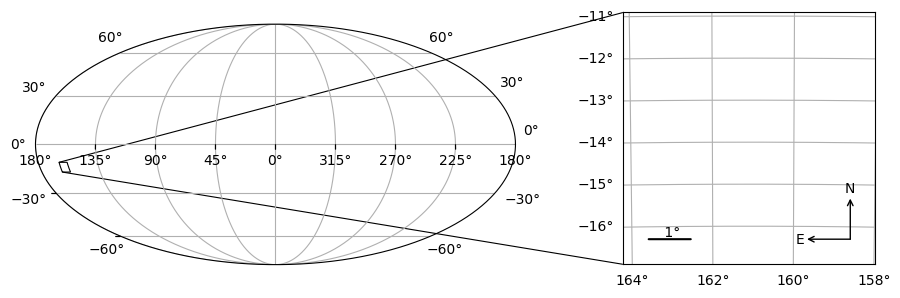

In [11]:
alert = ic_alerts['IceCube-140506J']
_ = plot_IC_alert(alert['healpix_url'], normalize=True, use_hpx_max=False)

IceCube-251027L  raised input value error. We skip
IceCube-251028C  raised input value error. We skip
IceCube-251028E  raised input value error. We skip
IceCube-251028I  raised input value error. We skip
IceCube-251028L  raised input value error. We skip
IceCube-251029E  raised input value error. We skip
IceCube-251029F  raised input value error. We skip
IceCube-251029G  raised input value error. We skip
IceCube-251029I  raised input value error. We skip
IceCube-251029J  raised input value error. We skip
IceCube-251030A  raised input value error. We skip
IceCube-251030C  raised input value error. We skip
IceCube-251030H  raised input value error. We skip
IceCube-251030I  raised input value error. We skip
IceCube-251030J  raised input value error. We skip
IceCube-251031C  raised input value error. We skip
IceCube-251031L  raised input value error. We skip
IceCube-251101C  raised input value error. We skip
IceCube-251101D  raised input value error. We skip
IceCube-251101E  raised input v

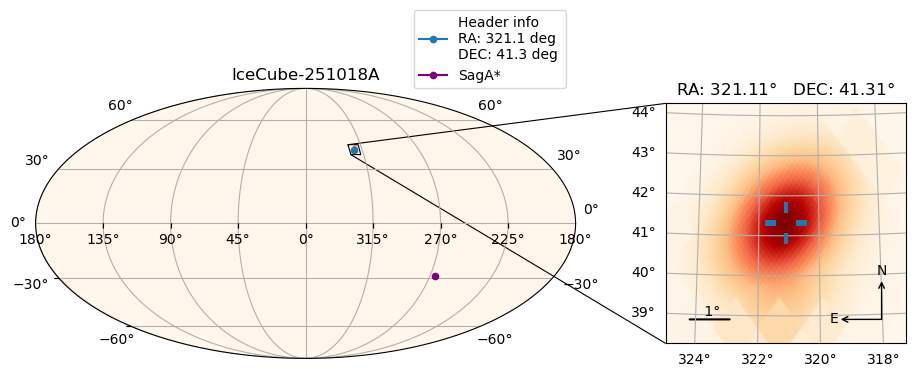

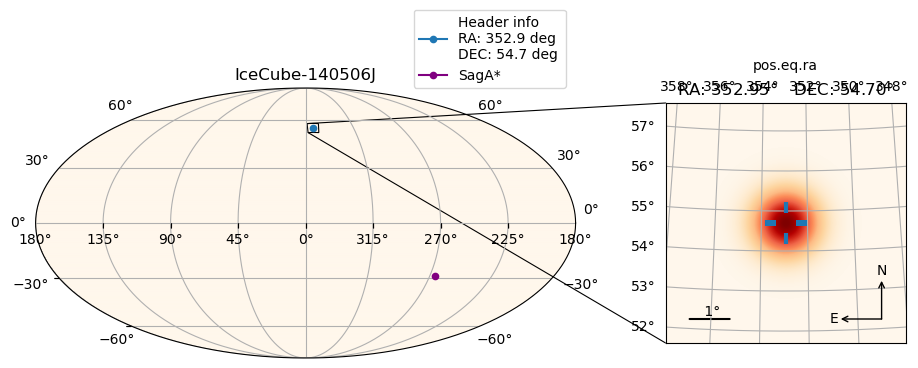

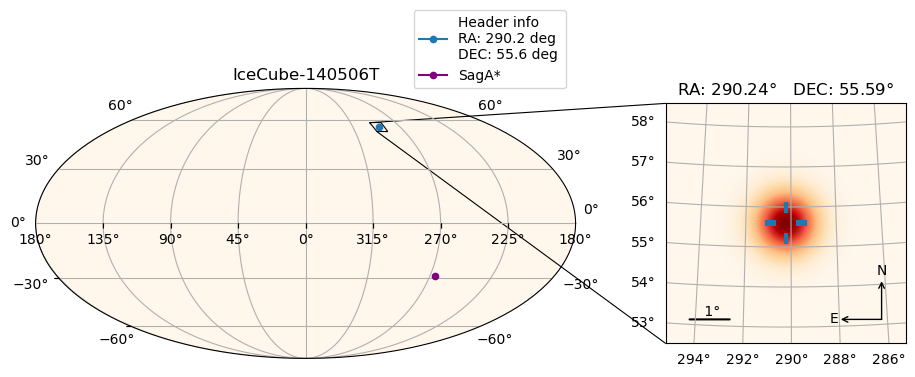

In [9]:
for alert_name in ic_alerts.keys():
    try:
        _ = plot_IC_alert(ic_alerts[alert_name]['healpix_url'], normalize=True, use_hpx_max=False)
        plt.close()
    except ValueError:
        print(alert_name, ' raised input value error. We skip')
        continue

In [6]:
test_case = ic_alerts['IceCube-251113E']
# plot_IC_alert(test_case['healpix_url'])
hpx, h = read_sky_map(test_case['healpix_url'], nest=True)

ValueError: ligo.skymap only reads and writes sky maps in equatorial coordinates.

In [15]:
map_name = test_case['healpix_url']
map_dir=p['map_dir']
if 'https' in map_name:
    file_name = map_name.split('/')[-1]
    title = file_name.split('_')[0]

    #first we download the map
    response = requests.get(map_name)
    map_path = os.path.join(map_dir, file_name)
    with open(map_path, 'wb') as file: #also deletes previously existing file and redownloads alert. 
        file.write(response.content)
    try:
        hpx, header = read_sky_map(map_path, nest=True)
    except ValueError as error:
        #It means that the header contains COORDSYS='c', and read_sky_map checks for COORDSYS == 'C'. 
        #we rewrite the header of the file and try again
        print('here 1')
        data, header = fits.getdata(map_path, header=True)
        print(header)
        if header['COORDSYS'] == 'c':
            header['COORDSYS'] = 'C'
            fits.writeto(map_path, data, header, overwrite=True)
            print('here 2')
            #we try again

here 1
XTENSION= 'BINTABLE'           / binary table extension                         BITPIX  =                    8 / array data type                                NAXIS   =                    2 / number of array dimensions                     NAXIS1  =                   16 / length of dimension 1                          NAXIS2  =                62685 / length of dimension 2                          PCOUNT  =                    0 / number of group parameters                     GCOUNT  =                    1 / number of groups                               TFIELDS =                    2 / number of table fields                         TTYPE1  = 'UNIQ    '                                                            TFORM1  = 'K       '                                                            TTYPE2  = 'PROBDENSITY'                                                         TFORM2  = 'D       '                                                            PIXTYPE = 'HEALPIX '           / 

In [24]:
data, header = fits.getdata(map_path, header=True)
data

FITS_rec([(8,   0.        ), (9,   0.        ), (10,   0.        ), ...,
          (134217725, 213.01323984), (134217726, 223.46508692),
          (134217727, 218.20500036)],
         dtype=(numpy.record, [('UNIQ', '>i8'), ('PROBDENSITY', '>f8')]))

In [19]:
hpx, _ = read_sky_map(map_path, nest=True)

ValueError: Input values did not match any of the formats where the format keyword is optional:
- 'datetime': Input values for datetime class must be datetime objects
- 'ymdhms': input must be dict or table-like
- 'iso': could not convert string to float: '.226871+00:00'
- 'isot': could not convert string to float: '.226871+00:00'
- 'yday': could not convert string to float: '.226871+00:00'
- 'datetime64': Input values for datetime64 class must be datetime64 objects
- 'fits': Time 2025-11-13T09:38:51.226871+00:00Z does not match fits format
- 'byear_str': Time 2025-11-13T09:38:51.226871+00:00Z does not match byear_str format
- 'jyear_str': Time 2025-11-13T09:38:51.226871+00:00Z does not match jyear_str format
- 'astropy_time': Input values for astropy_time class must all be the same astropy Time type.

In [11]:
good_alert = ic_alerts['IceCube-251018A']
# plot_IC_alert(good_alert['healpix_url'], normalize=True, use_hpx_max=False)
data, header = fits.getdata(good_alert['healpix_url'], header=True)
header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                   16 / length of dimension 1                          
NAXIS2  =                 5157 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                    1 / number of groups                               
TFIELDS =                    2 / number of table fields                         
TTYPE1  = 'UNIQ    '                                                            
TFORM1  = 'K       '                                                            
TTYPE2  = 'PROBDENSITY'                                                         
TFORM2  = 'D       '                                                            
TUNIT2  = 'sr-1    '        

In [12]:
hpx.shape

NameError: name 'hpx' is not defined

In [35]:
data.meta.pop("ORDERING")

AttributeError: recarray has no attribute meta

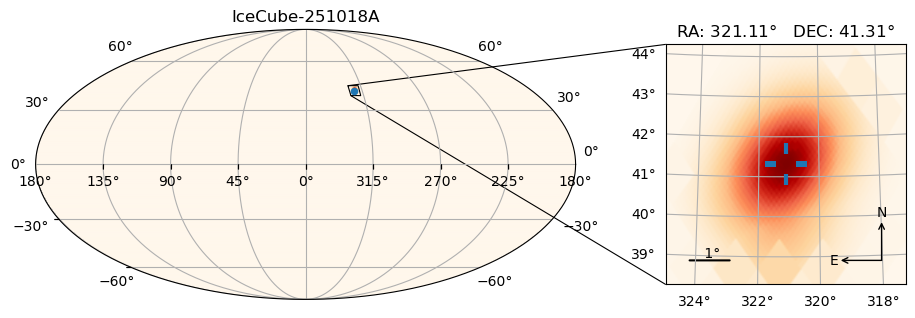

'IceCube-251018A'

In [13]:
hpx_hp, h_hp = hp.read_map(good_alert['healpix_url'], h=True, nest=True)
plot_IC_alert(good_alert['healpix_url'], normalize=True, use_hpx_max=False)

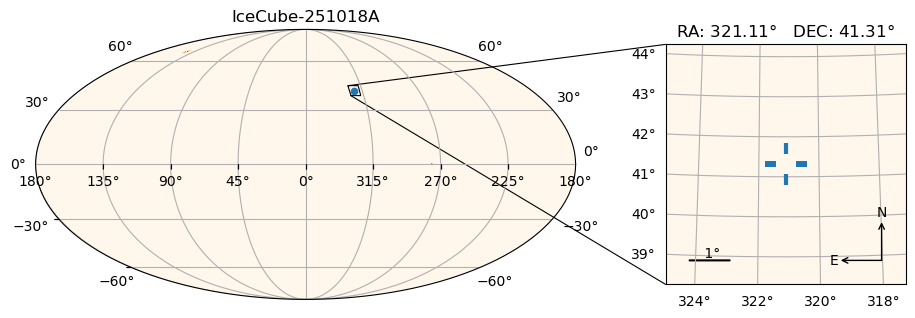

'IceCube-251018A'

In [14]:
plot_IC_alert(good_alert['healpix_url'], normalize=True, use_hpx_max=False, use_own_hpx=True, hpx=hpx_hp, header=h_hp, 
              title=f"{good_alert['event_name']}")

In [39]:
h_hp

[('XTENSION', 'BINTABLE'),
 ('BITPIX', 8),
 ('NAXIS', 2),
 ('NAXIS1', 16),
 ('NAXIS2', 5157),
 ('PCOUNT', 0),
 ('GCOUNT', 1),
 ('TFIELDS', 2),
 ('TTYPE1', 'UNIQ'),
 ('TFORM1', 'K'),
 ('TTYPE2', 'PROBDENSITY'),
 ('TFORM2', 'D'),
 ('TUNIT2', 'sr-1'),
 ('PIXTYPE', 'HEALPIX'),
 ('ORDERING', 'NUNIQ'),
 ('NSIDE', 1024),
 ('INDXSCHM', 'EXPLICIT'),
 ('MOCORDER', 10),
 ('RUNID', 141495),
 ('EVENTID', 22018019),
 ('SENDER', 'IceCube Collaboration'),
 ('DATE-OBS', '2025-10-18T05:05:42.974'),
 ('MJD-OBS', 60966.21230294052),
 ('I3TYPE', 'neutrino'),
 ('RA', 321.11),
 ('DEC', 41.31),
 ('RA_ERR_PLUS_50', 1.78),
 ('RA_ERR_MINUS_50', 1.63),
 ('DEC_ERR_PLUS_50', 1.42),
 ('DEC_ERR_MINUS_50', 1.49),
 ('RA_ERR_PLUS_90', 3.09),
 ('RA_ERR_MINUS_90', 2.95),
 ('DEC_ERR_PLUS_90', 2.46),
 ('DEC_ERR_MINUS_90', 3.51),
 ('CONTOUR_AREA_50', 5.58),
 ('CONTOUR_AREA_90', 19.63),
 ('COMMENTS',
  '50% and 90% uncertainty location => Highest posterior density 50% and 90% credible region'),
 ('NOTE',
  'Please ignore pixe

In [6]:
alert = {"$schema": "https://gcn.nasa.gov/schema/main/gcn/notices/icecube/single_neutrino_alerts.schema.json", 
"mission": "IceCube", 
"instrument": "IC86", 
"messenger": "Neutrino", 
"pipeline": "Bronze Track Alert", 
"record_number": 0, 
"event_name": "IceCube-140506Z", 
"id": "20878_1", 
"alert_datetime": "2025-12-08T11:12:20.921017Z", 
"alert_type": "update", 
"alert_tense": "injection", 
"alert_topology": "Track", 
"number_of_events": 1, 
"ra": 185.86, 
"dec": 62.44, 
"ra_dec_error": 0.52, 
"containment_probability": 0.9, 
"systematic_included": True, 
"healpix_url": "https://roc.icecube.wisc.edu/public/alerts/injected/IceCube-140506Z_skymap_probdensity_multiorder.fits.gz", 
"trigger_time": "2025-12-08T10:11:50.054875Z", 
"nu_energy": 137.16, 
"p_astro": 0.4817, 
"far": "6.57e-09"}

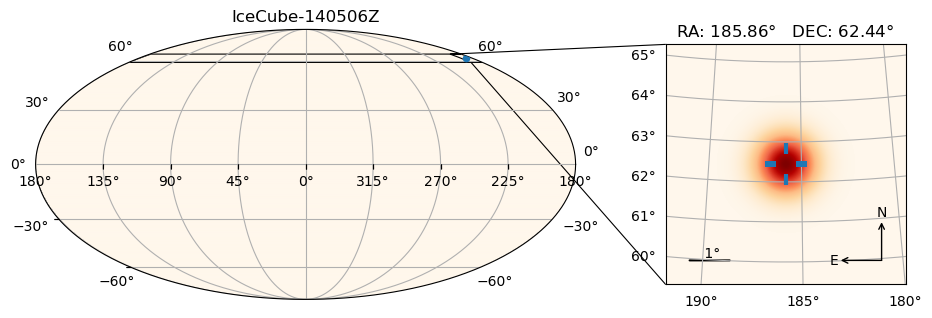

'IceCube-140506Z'

In [9]:
plot_IC_alert(alert['healpix_url'])

In [7]:
with open('selected_alerts.json', 'r') as file:
    alerts = json.load(file)

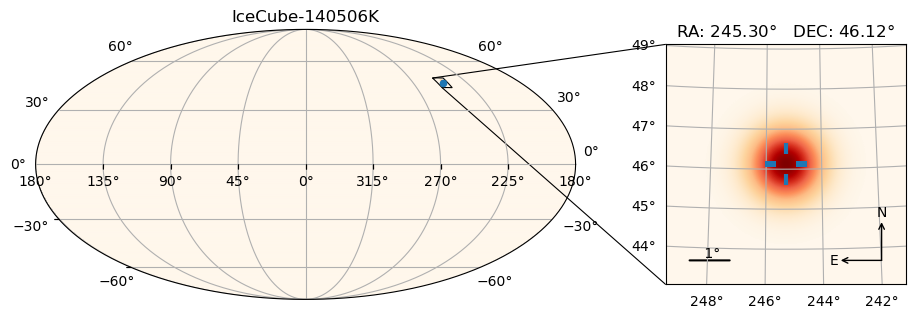

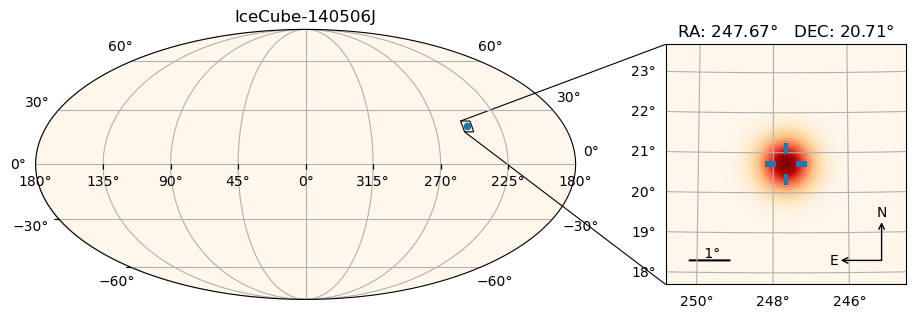

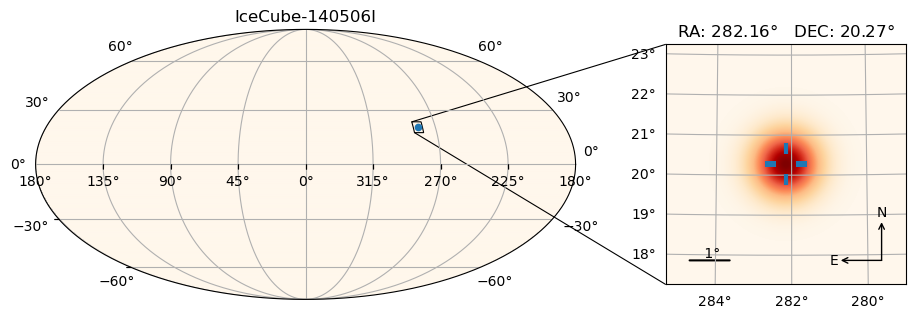

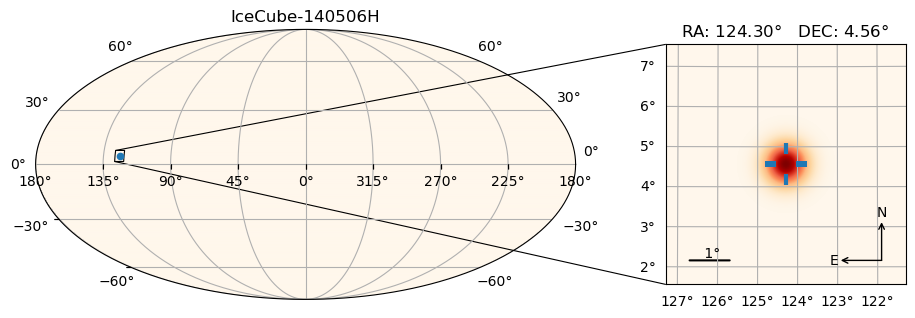

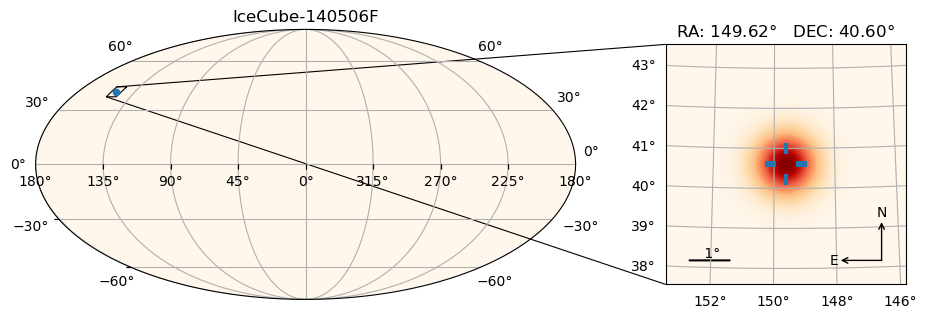

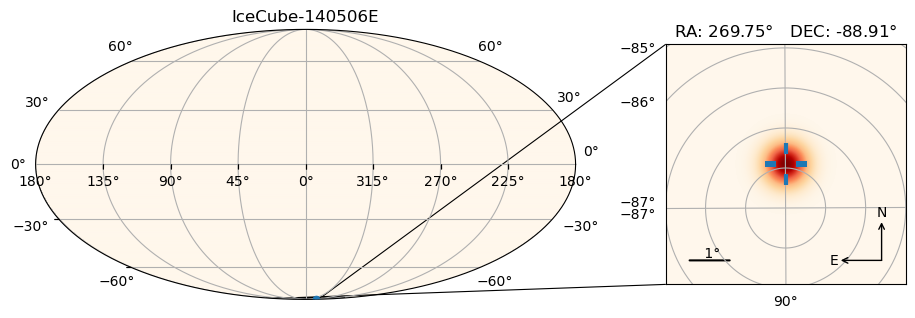

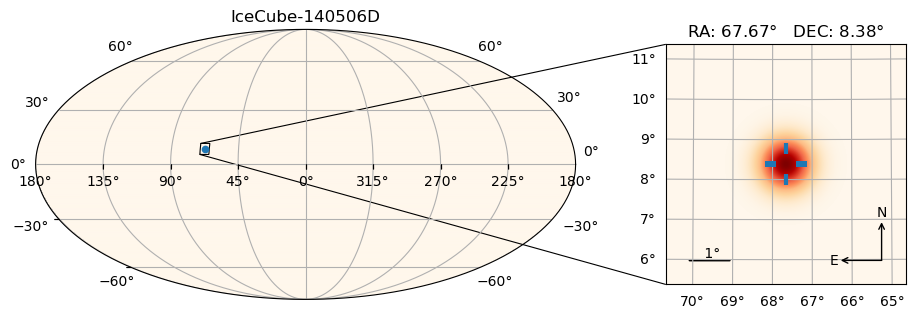

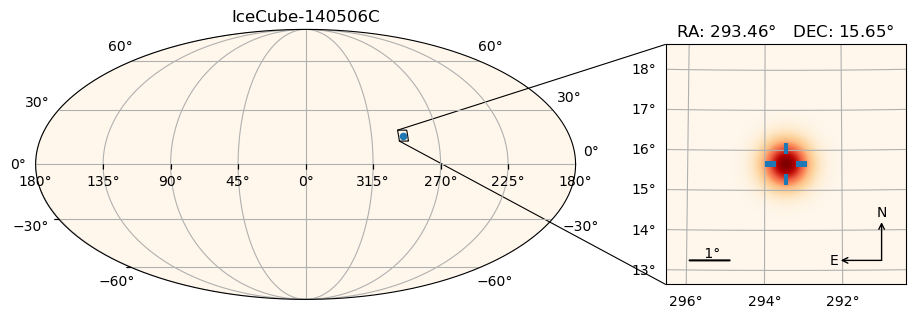

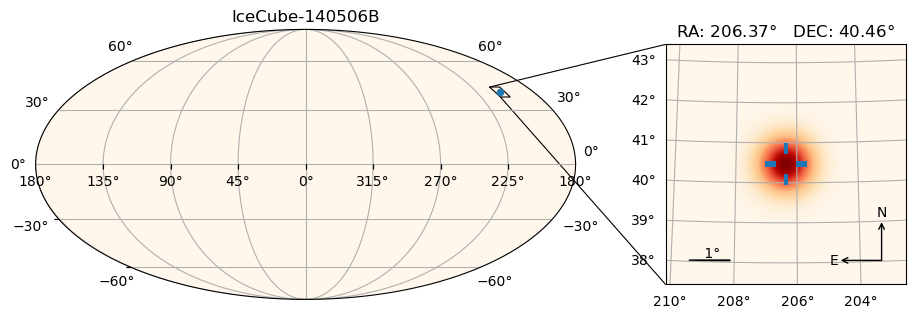

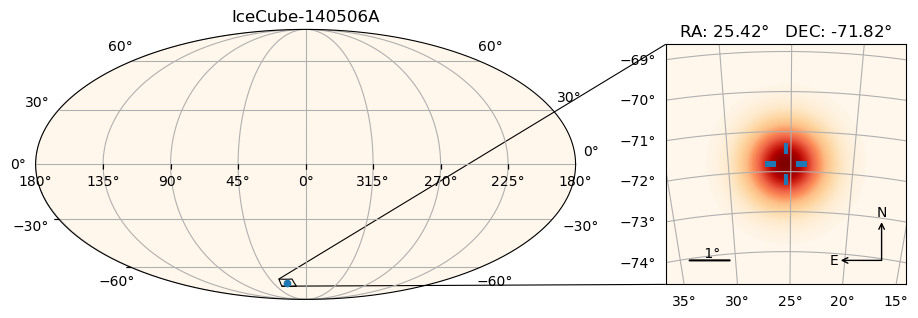

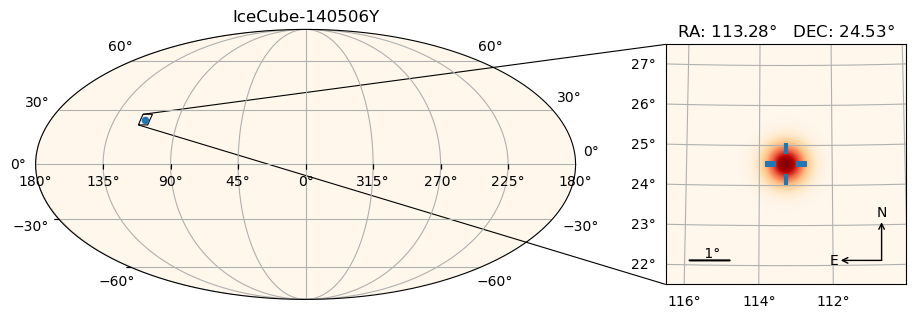

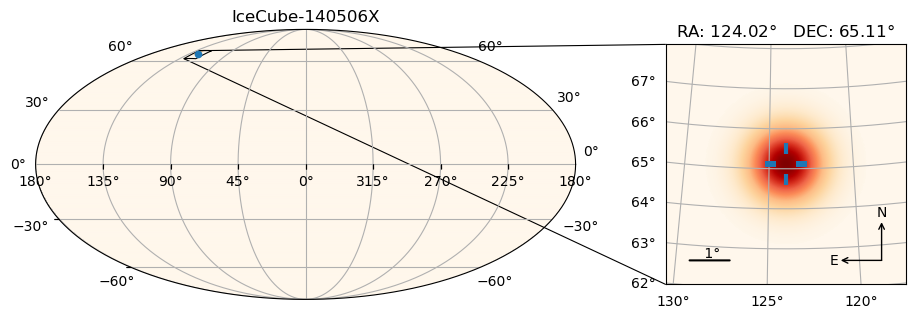

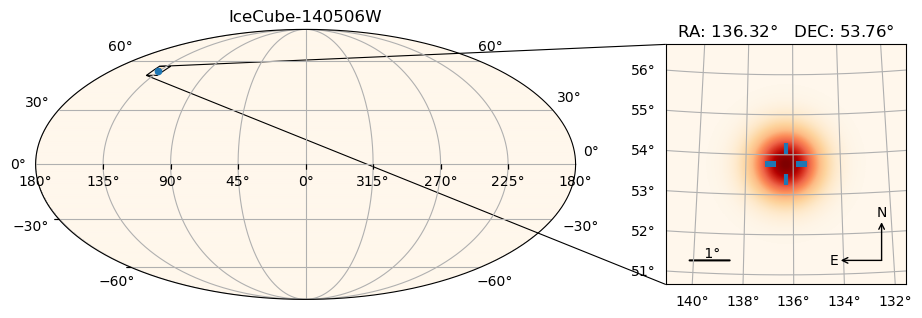

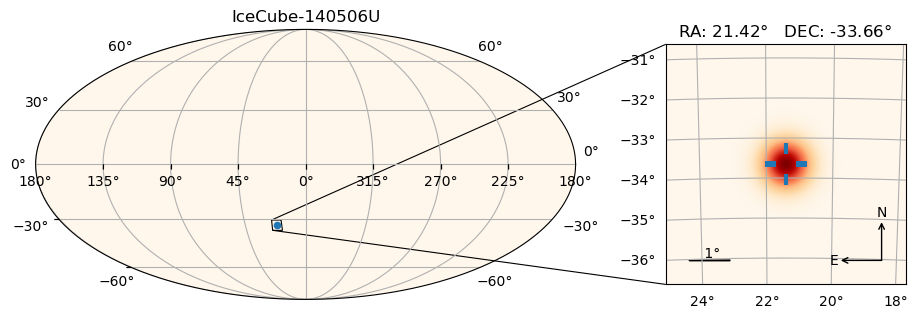

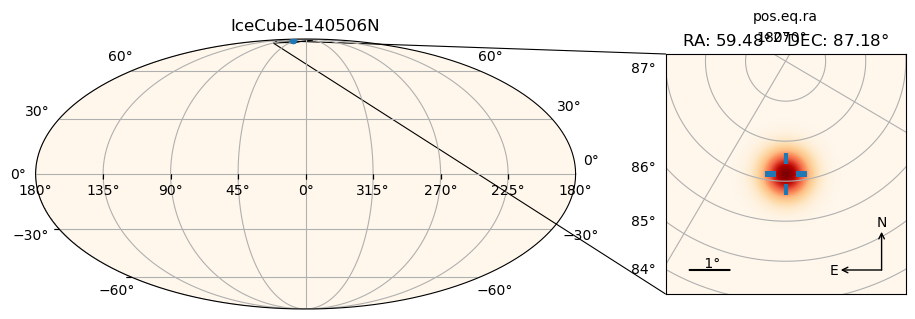

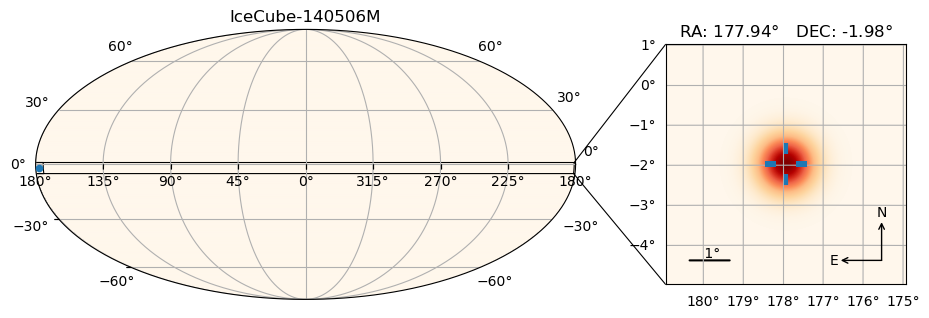

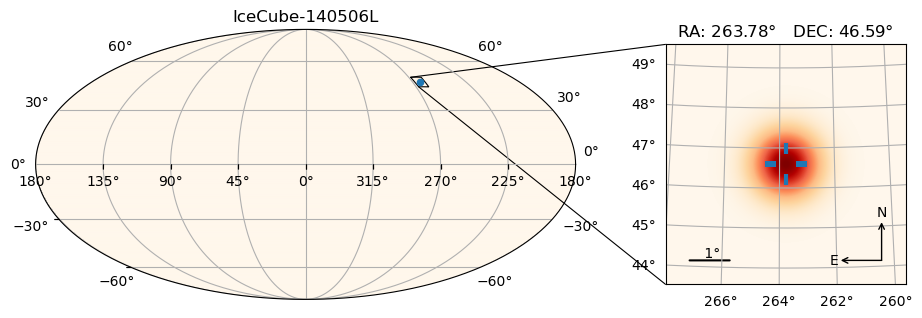

In [27]:
for alert_name in alerts.keys():
    plot_IC_alert(alerts[alert_name]['healpix_url'], use_hpx_max=False)

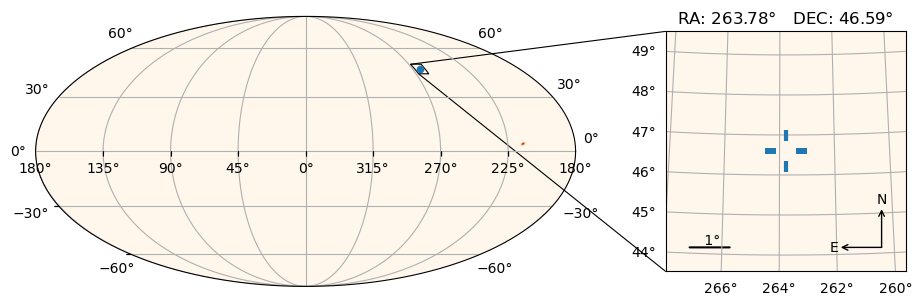

''

In [29]:
test_alert = alerts['IceCube-140506L']
hpx, h = hp.read_map(test_alert['healpix_url'], nest=True, h=True)
# hp.mollview(hpx, nest=True)
plot_IC_alert(test_alert, use_hpx_max=False, use_own_hpx=True, hpx=hpx, header=h)

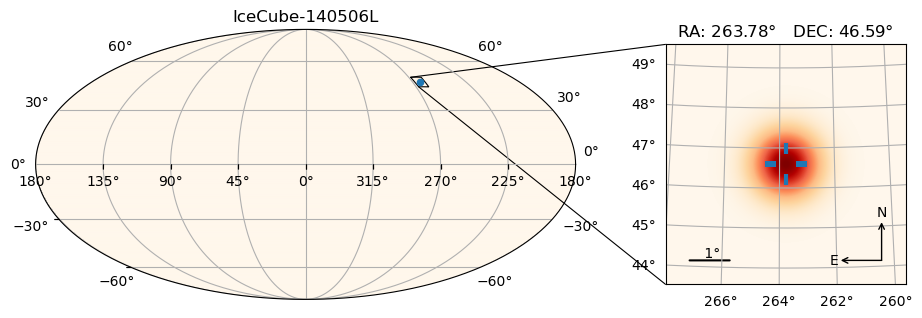

'IceCube-140506L'

In [30]:
plot_IC_alert(test_alert['healpix_url'], use_hpx_max=False)

## mhealpy

(<matplotlib.image.AxesImage at 0x1452dc350>, <Mollview: >)

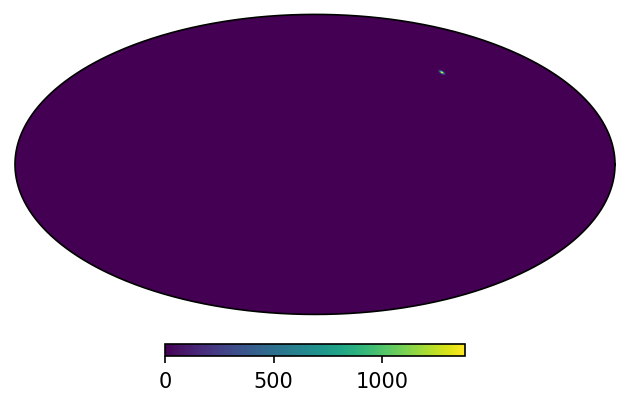

In [18]:
test_alert = alerts['IceCube-140506L']
m = HealpixMap.read_map(test_alert['healpix_url'], density = False)
# mm = m.to_moc(max_value = max(m))
# 
m.plot()
# mm.plot_grid(plt.gca(), linewidth = .1, color = 'white')

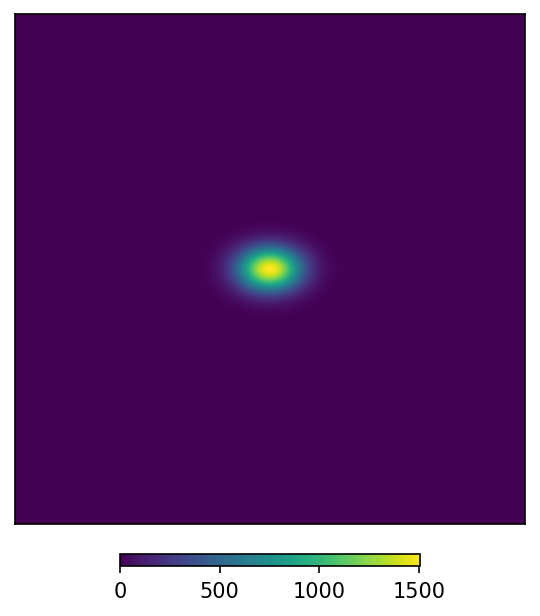

In [14]:
import numpy as np

theta_max,phi_max = m.pix2ang(np.argmax(m))

lonra = np.rad2deg(phi_max) + np.array([-10,10])
latra = (90-np.rad2deg(theta_max)) + np.array([-10,10])

m.plot(ax = 'cartview', ax_kw = {'latra': latra, 'lonra': lonra});

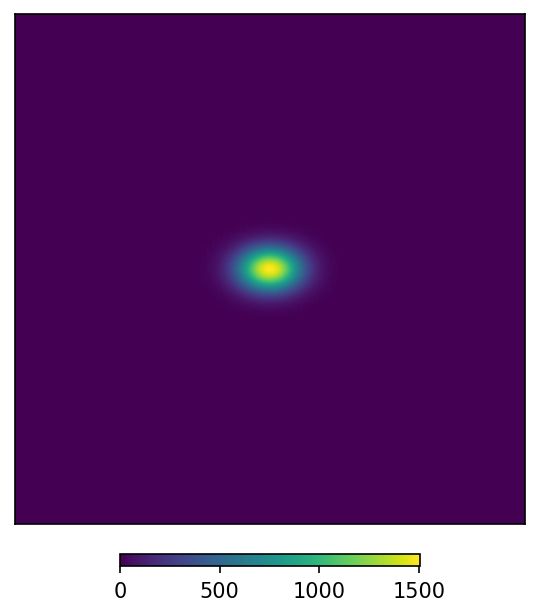

In [15]:
mm = m.to_moc(max_value = max(m))

mm.plot(ax = 'cartview', ax_kw = {'latra': latra, 'lonra': lonra});

ValueError: setting an array element with a sequence.

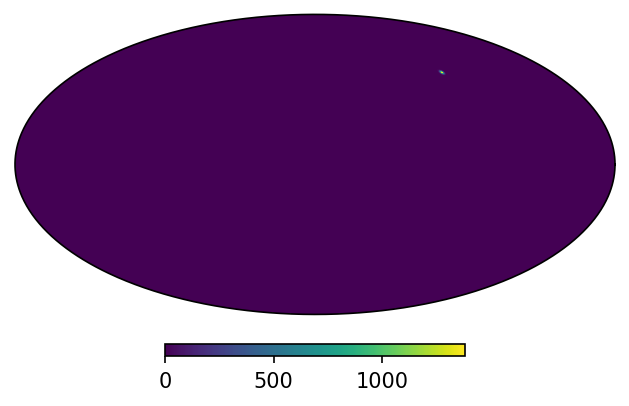

In [16]:
import matplotlib.pyplot as plt

mm.plot()
mm.plot_grid(plt.gca(), linewidth = .1, color = 'white');

In [19]:
help(HealpixMap)

Help on class HealpixMap in module mhealpy.containers.healpix_map:

class HealpixMap(mhealpy.containers.healpix_base.HealpixBase)
 |  HealpixMap(data=None, uniq=None, order=None, nside=None, scheme='ring', base=None, density=False, dtype=None, coordsys=None, unit=None)
 |
 |  Object-oriented healpy wrapper with support for multi-resolutions maps
 |  (known as multi-order coverage map, or MOC).
 |
 |  You can instantiate a map by providing either:
 |
 |  * Size (through ``order`` or ``nside``), and a ``scheme`` ('RING' or 'NESTED').
 |    This will initialize an empty map.
 |  * A list of UNIQ pixels. This will initialize a MOC map. Providing the
 |    values for each pixel is optional, zero-initialized by default.
 |  * An array (in ``data``) and an a scheme ('RING' or 'NESTED'). This will
 |    initialize the contents of the single-resolution map.
 |  * A HealpixBase object. The data will be zero-initialized.
 |
 |  .. warning::
 |      The initialization input is not validated by def